<a href="https://colab.research.google.com/github/Zaharaaz/Aretina/blob/main/aretina_801010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================================
# ARETINA — Klasifikasi Penyakit Mata (Cataract, Conjunctivitis, Normal)
# Versi Split 80:10:10 | Arsitektur: MobileNetV2
# ============================================================================
# Script ini disusun runtut dari pengambilan data sampai persiapan data
# (Data Understanding -> Data Preparation: Transformation & Reduction)
# beserta visualisasi before-after untuk dilampirkan di skripsi.

In [ ]:
import os
import shutil
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# ============================================================================
# 1. DATA COLLECTION — Ambil dataset dari Google Drive
# ============================================================================
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ZIP_PATH = '/content/drive/MyDrive/DATASET/Dataset.zip'
LOCAL_DATA_DIR = '/content/dataset'

if not os.path.exists(LOCAL_DATA_DIR):
    print(f"Mengekstrak {DRIVE_ZIP_PATH} ...")
    with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_DATA_DIR)
    print(f"Dataset diekstrak ke: {LOCAL_DATA_DIR}")
else:
    print("Folder dataset sudah ada, ekstraksi dilewati.")

# Struktur asli hasil ekstraksi: /content/dataset/Dataset/train|val|test/<kelas>
BASE_DATA_DIR = os.path.join(LOCAL_DATA_DIR, 'Dataset')
ORIG_TRAIN_DIR = os.path.join(BASE_DATA_DIR, 'train')
ORIG_VAL_DIR   = os.path.join(BASE_DATA_DIR, 'val')
ORIG_TEST_DIR  = os.path.join(BASE_DATA_DIR, 'test')

CLASS_NAMES_RAW = ['cataract', 'conjunctivitis', 'normal']

Mounted at /content/drive
Mengekstrak /content/drive/MyDrive/DATASET/Dataset.zip ...
Dataset diekstrak ke: /content/dataset


In [ ]:
# ============================================================================
# 2. DATA CLEANING — buang file yang bukan .jpg/.jpeg/.png
# ============================================================================
VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

def clean_dataset_directory(root_dir: str) -> int:
    removed_count = 0
    for dirpath, _, filenames in os.walk(root_dir):
        for filename in filenames:
            if Path(filename).suffix.lower() not in VALID_EXTENSIONS:
                full_path = os.path.join(dirpath, filename)
                os.remove(full_path)
                removed_count += 1
    return removed_count

total_removed = 0
for split_dir in [ORIG_TRAIN_DIR, ORIG_VAL_DIR, ORIG_TEST_DIR]:
    total_removed += clean_dataset_directory(split_dir)
print(f"Pembersihan selesai. Total file tidak valid dihapus: {total_removed}")

Pembersihan selesai. Total file tidak valid dihapus: 0


In [ ]:
# ============================================================================
# 3. RE-SPLIT 80:10:10 — gabungkan semua split lama, lalu bagi ulang
# ============================================================================
# Kenapa perlu digabung dulu: split asli (70:15:15) sudah memisah file ke
# folder train/val/test. Untuk membuat rasio baru (80:10:10), seluruh file
# per kelas dikumpulkan dulu ke satu pool, baru dibagi ulang secara acak
# dengan proporsi yang diinginkan. Total data TIDAK berubah, hanya
# proporsinya yang disesuaikan.

SEED = 42
random.seed(SEED)

RESPLIT_DIR = '/content/dataset_80_10_10'
SPLIT_RATIOS = {'train': 0.80, 'val': 0.10, 'test': 0.10}

def collect_all_files_per_class(class_name):
    """Kumpulkan path semua file dari train/val/test asli untuk satu kelas."""
    all_files = []
    for split_dir in [ORIG_TRAIN_DIR, ORIG_VAL_DIR, ORIG_TEST_DIR]:
        class_dir = os.path.join(split_dir, class_name)
        if os.path.exists(class_dir):
            for fname in os.listdir(class_dir):
                if Path(fname).suffix.lower() in VALID_EXTENSIONS:
                    all_files.append(os.path.join(class_dir, fname))
    return all_files

def resplit_dataset():
    if os.path.exists(RESPLIT_DIR):
        print("Folder hasil re-split sudah ada, proses dilewati.")
        return

    distribution_log = {}

    for class_name in CLASS_NAMES_RAW:
        files = collect_all_files_per_class(class_name)
        random.shuffle(files)  # acak urutan sebelum dibagi (pakai SEED tetap)

        n_total = len(files)
        n_train = int(n_total * SPLIT_RATIOS['train'])
        n_val   = int(n_total * SPLIT_RATIOS['val'])
        # sisanya masuk test, supaya seluruh file tetap kepakai (tidak ada yang hilang akibat pembulatan)
        n_test  = n_total - n_train - n_val

        split_files = {
            'train': files[:n_train],
            'val':   files[n_train:n_train + n_val],
            'test':  files[n_train + n_val:]
        }

        distribution_log[class_name] = {
            'total': n_total, 'train': n_train, 'val': n_val, 'test': n_test
        }

        for split_name, file_list in split_files.items():
            dest_dir = os.path.join(RESPLIT_DIR, split_name, class_name)
            os.makedirs(dest_dir, exist_ok=True)
            for src_path in file_list:
                shutil.copy(src_path, dest_dir)

    print("Re-split 80:10:10 selesai.\n")
    print(f"{'Kelas':<16}{'Total':>8}{'Train':>8}{'Val':>8}{'Test':>8}")
    for cname, d in distribution_log.items():
        print(f"{cname:<16}{d['total']:>8}{d['train']:>8}{d['val']:>8}{d['test']:>8}")

    return distribution_log

distribution_log = resplit_dataset()

TRAIN_DIR = os.path.join(RESPLIT_DIR, 'train')
VAL_DIR   = os.path.join(RESPLIT_DIR, 'val')
TEST_DIR  = os.path.join(RESPLIT_DIR, 'test')

Re-split 80:10:10 selesai.

Kelas              Total   Train     Val    Test
cataract             848     678      84      86
conjunctivitis       462     369      46      47
normal              1002     801     100     101


In [ ]:
# ==========================================================
# CEK DUPLIKAT & NEAR-DUPLICATE DATASET (jalankan di Colab)
# Tempel di CELL BARU di notebook Colab kamu, SETELAH proses
# resplit selesai (setelah variabel TRAIN_DIR, VAL_DIR, TEST_DIR ada)
# ==========================================================

!pip install imagehash -q

import os
import hashlib
from pathlib import Path
from PIL import Image
import imagehash
import pandas as pd

SPLIT_DIRS = {
    'train': TRAIN_DIR,
    'val': VAL_DIR,
    'test': TEST_DIR,
}

VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

def collect_files(split_dirs):
    """Kumpulkan semua path file gambar beserta info split & kelas-nya."""
    records = []
    for split_name, split_path in split_dirs.items():
        for class_name in os.listdir(split_path):
            class_dir = os.path.join(split_path, class_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in os.listdir(class_dir):
                if Path(fname).suffix.lower() in VALID_EXTENSIONS:
                    records.append({
                        'split': split_name,
                        'class': class_name,
                        'filename': fname,
                        'path': os.path.join(class_dir, fname),
                    })
    return records

def compute_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def compute_phash(path):
    try:
        img = Image.open(path).convert('RGB')
        return str(imagehash.phash(img))
    except Exception as e:
        return None

print("Mengumpulkan daftar file...")
records = collect_files(SPLIT_DIRS)
df = pd.DataFrame(records)
print(f"Total file terkumpul: {len(df)}")

# ---------- 1. EXACT DUPLICATE (MD5) ----------
print("\nMenghitung MD5 hash (exact duplicate)...")
df['md5'] = df['path'].apply(compute_md5)

exact_dupes = df[df.duplicated('md5', keep=False)].sort_values('md5')
print(f"Jumlah file yang punya exact duplicate: {len(exact_dupes)}")

# tandai duplikat yang LINTAS SPLIT (paling berbahaya untuk data leakage)
cross_split_exact = []
for md5_val, group in exact_dupes.groupby('md5'):
    splits_involved = set(group['split'])
    if len(splits_involved) > 1:
        cross_split_exact.append(group)

if cross_split_exact:
    cross_split_exact_df = pd.concat(cross_split_exact)
    print(f"⚠️  Exact duplicate LINTAS SPLIT (train/val/test bercampur): {len(cross_split_exact_df)} file")
else:
    cross_split_exact_df = pd.DataFrame()
    print("✅ Tidak ada exact duplicate lintas split.")

# ---------- 2. NEAR-DUPLICATE (Perceptual Hash) ----------
print("\nMenghitung perceptual hash (near-duplicate, ini agak lama)...")
df['phash'] = df['path'].apply(compute_phash)

near_dupes = df[df.duplicated('phash', keep=False)].sort_values('phash')
print(f"Jumlah file yang punya near-duplicate (phash identik): {len(near_dupes)}")

cross_split_near = []
for phash_val, group in near_dupes.groupby('phash'):
    splits_involved = set(group['split'])
    if len(splits_involved) > 1:
        cross_split_near.append(group)

if cross_split_near:
    cross_split_near_df = pd.concat(cross_split_near)
    print(f"⚠️  Near-duplicate LINTAS SPLIT: {len(cross_split_near_df)} file")
else:
    cross_split_near_df = pd.DataFrame()
    print("✅ Tidak ada near-duplicate lintas split (berdasarkan phash sama persis).")

# ---------- 3. SIMPAN HASIL KE CSV UNTUK DIPERIKSA ----------
df.to_csv('/content/dataset_hash_full.csv', index=False)
exact_dupes.to_csv('/content/exact_duplicates.csv', index=False)
near_dupes.to_csv('/content/near_duplicates.csv', index=False)
if len(cross_split_exact_df):
    cross_split_exact_df.to_csv('/content/cross_split_exact_duplicates.csv', index=False)
if len(cross_split_near_df):
    cross_split_near_df.to_csv('/content/cross_split_near_duplicates.csv', index=False)

print("\n================ RINGKASAN ================")
print(f"Total citra dicek           : {len(df)}")
print(f"Exact duplicate (total)     : {len(exact_dupes)}")
print(f"Exact duplicate lintas split: {len(cross_split_exact_df)}")
print(f"Near-duplicate (total)      : {len(near_dupes)}")
print(f"Near-duplicate lintas split : {len(cross_split_near_df)}")
print("=============================================")
print("\nFile CSV hasil sudah disimpan di /content/ — bisa didownload dari panel Files di Colab.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 9.7 MB/s eta 0:00:00
Mengumpulkan daftar file...
Total file terkumpul: 1986

Menghitung MD5 hash (exact duplicate)...
Jumlah file yang punya exact duplicate: 386
⚠️  Exact duplicate LINTAS SPLIT (train/val/test bercampur): 321 file

Menghitung perceptual hash (near-duplicate, ini agak lama)...
Jumlah file yang punya near-duplicate (phash identik): 454
⚠️  Near-duplicate LINTAS SPLIT: 358 file

================ RINGKASAN ================
Total citra dicek           : 1986
Exact duplicate (total)     : 386
Exact duplicate lintas split: 321
Near-duplicate (total)      : 454
Near-duplicate lintas split : 358

File CSV hasil sudah disimpan di /content/ — bisa didownload dari panel Files di Colab.


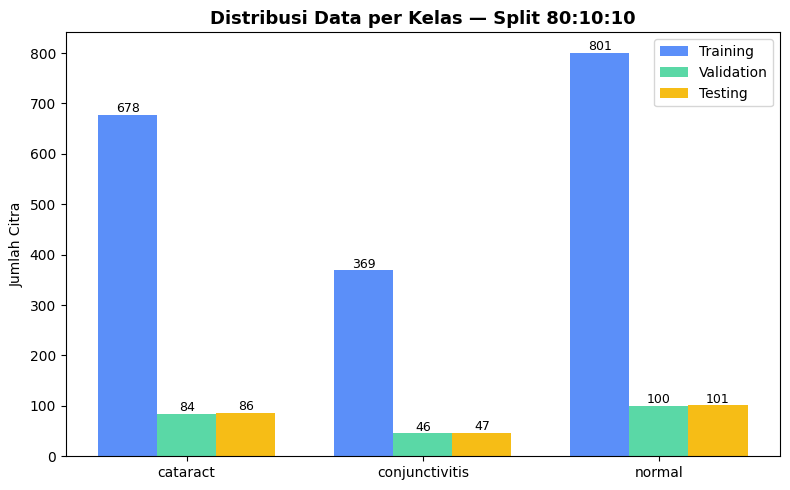

Gambar distribusi kelas disimpan: distribusi_kelas_80_10_10.png


In [ ]:
# ---------------------------------------------------------------------------
# Visualisasi tabel distribusi kelas (pengganti Tabel 3.3, versi 80:10:10)
# ---------------------------------------------------------------------------
def plot_class_distribution_table(distribution_log):
    classes = list(distribution_log.keys())
    train_counts = [distribution_log[c]['train'] for c in classes]
    val_counts   = [distribution_log[c]['val'] for c in classes]
    test_counts  = [distribution_log[c]['test'] for c in classes]

    x = np.arange(len(classes))
    width = 0.25

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(x - width, train_counts, width, label='Training', color='#5B8FF9')
    ax.bar(x,         val_counts,   width, label='Validation', color='#5AD8A6')
    ax.bar(x + width, test_counts,  width, label='Testing', color='#F6BD16')

    for i, v in enumerate(train_counts):
        ax.text(x[i]-width, v+5, str(v), ha='center', fontsize=9)
    for i, v in enumerate(val_counts):
        ax.text(x[i], v+5, str(v), ha='center', fontsize=9)
    for i, v in enumerate(test_counts):
        ax.text(x[i]+width, v+5, str(v), ha='center', fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.set_ylabel('Jumlah Citra')
    ax.set_title('Distribusi Data per Kelas — Split 80:10:10', fontsize=13, fontweight='bold')
    ax.legend()
    plt.tight_layout()
    plt.savefig('/content/distribusi_kelas_80_10_10.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gambar distribusi kelas disimpan: distribusi_kelas_80_10_10.png")

plot_class_distribution_table(distribution_log)

Found 1532 files belonging to 3 classes.
Found 227 files belonging to 3 classes.
Found 231 files belonging to 3 classes.
Kelas terdeteksi (3): ['cataract', 'conjunctivitis', 'normal']


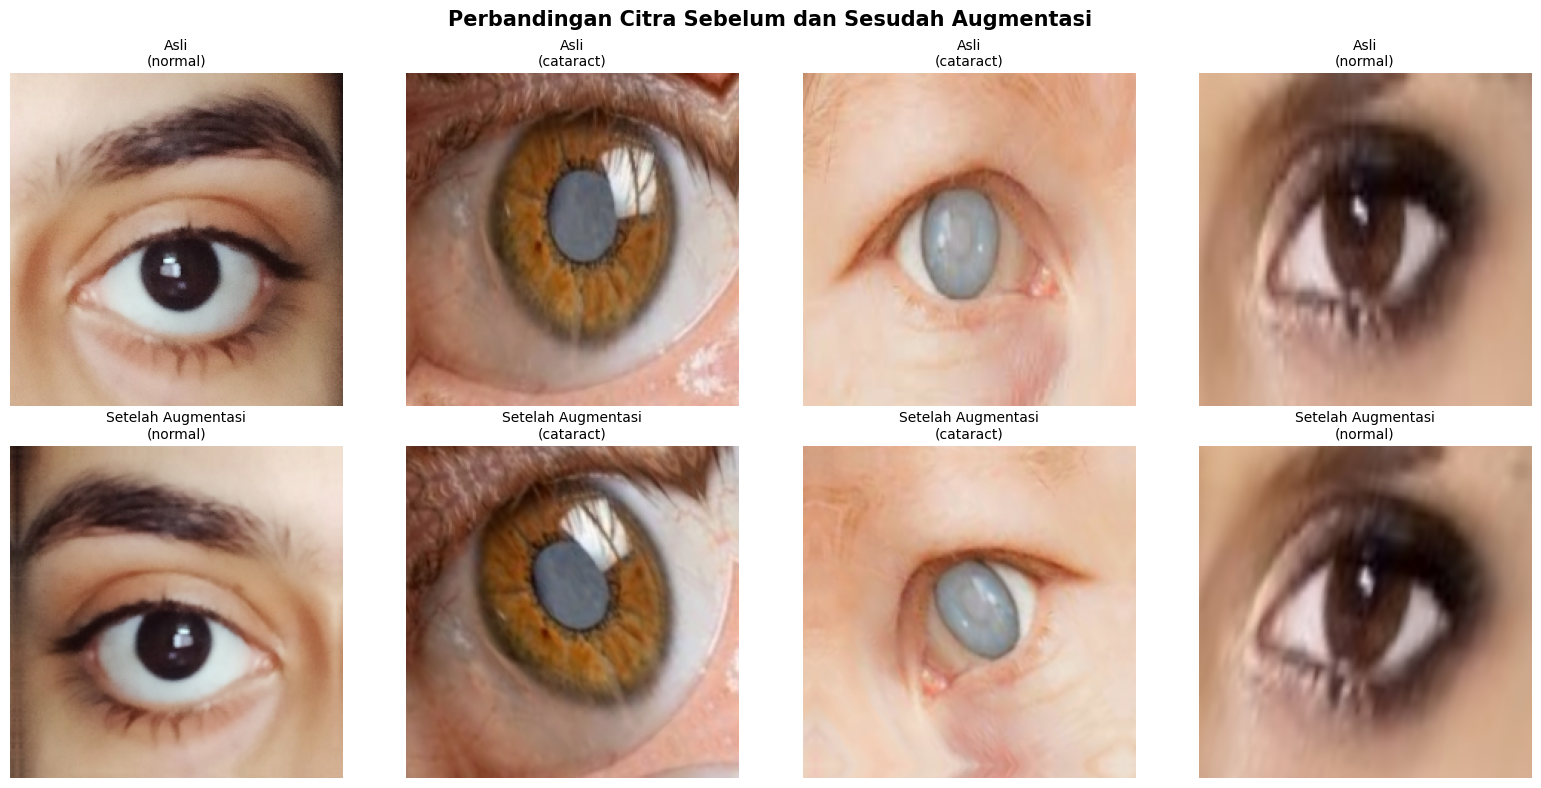

Gambar disimpan: before_after_augmentation.png


In [ ]:
# ============================================================================
# III.3.3.3 DATA TRANSFORMATION
# ============================================================================
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)

CLASS_NAMES = raw_train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)
print(f"Kelas terdeteksi ({NUM_CLASSES}): {CLASS_NAMES}")

# Layer augmentasi — didefinisikan satu kali, dipakai di dalam arsitektur model
# sehingga otomatis nonaktif saat evaluasi val/test.
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name='data_augmentation')

def show_before_after_augmentation(dataset, augmentation_layer, class_names, n_samples=4):
    """Tampilkan citra asli (atas) vs hasil augmentasi (bawah) untuk citra yang sama."""
    images, labels = next(iter(dataset))
    fig, axes = plt.subplots(2, n_samples, figsize=(4 * n_samples, 8))
    fig.suptitle("Perbandingan Citra Sebelum dan Sesudah Augmentasi", fontsize=15, fontweight='bold')

    for i in range(n_samples):
        original_img = images[i].numpy().astype('uint8')
        label_idx = tf.argmax(labels[i]).numpy()
        label_name = class_names[label_idx]

        axes[0, i].imshow(original_img)
        axes[0, i].set_title(f"Asli\n({label_name})", fontsize=10)
        axes[0, i].axis('off')

        augmented_img = augmentation_layer(tf.expand_dims(images[i], 0), training=True)
        axes[1, i].imshow(augmented_img[0].numpy().astype('uint8'))
        axes[1, i].set_title(f"Setelah Augmentasi\n({label_name})", fontsize=10)
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig('/content/before_after_augmentation.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gambar disimpan: before_after_augmentation.png")

show_before_after_augmentation(raw_train_ds, data_augmentation, CLASS_NAMES, n_samples=4)


Bobot kelas (semakin tinggi = semakin dihukum saat training):
  Kelas 0 'cataract':   526 sampel -> bobot = 0.9708
  Kelas 1 'conjunctivitis':   263 sampel -> bobot = 1.9417
  Kelas 2 'normal':   743 sampel -> bobot = 0.6873


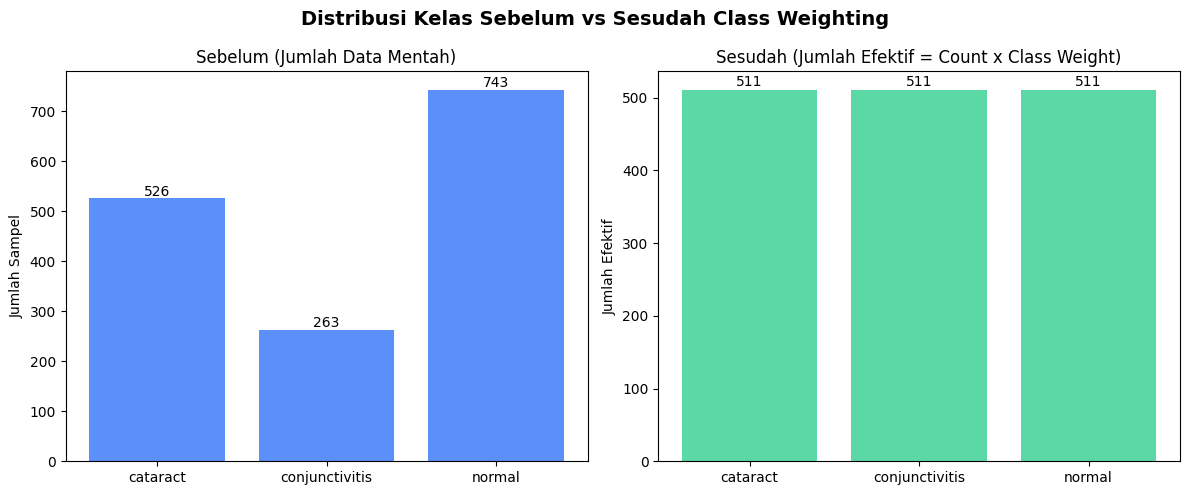

Gambar disimpan: before_after_class_weighting.png


In [ ]:
# ============================================================================
# III.3.3.4 DATA REDUCTION
# ============================================================================
# A. Class weighting (balanced)
all_train_labels = []
for _, label_batch in raw_train_ds:
    all_train_labels.extend(tf.argmax(label_batch, axis=1).numpy())
all_train_labels = np.array(all_train_labels)

weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_train_labels),
    y=all_train_labels
)
class_weights = {i: weights[i] for i in range(NUM_CLASSES)}

print("\nBobot kelas (semakin tinggi = semakin dihukum saat training):")
for idx, name in enumerate(CLASS_NAMES):
    count = np.sum(all_train_labels == idx)
    print(f"  Kelas {idx} '{name}': {count:>5} sampel -> bobot = {class_weights[idx]:.4f}")

def show_before_after_class_balance(class_names, raw_counts, weights_dict):
    """Bar chart kiri: jumlah mentah. Bar chart kanan: jumlah efektif (count x weight)."""
    counts = [raw_counts[i] for i in range(len(class_names))]
    effective = [raw_counts[i] * weights_dict[i] for i in range(len(class_names))]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle("Distribusi Kelas Sebelum vs Sesudah Class Weighting", fontsize=14, fontweight='bold')

    bars1 = axes[0].bar(class_names, counts, color='#5B8FF9')
    axes[0].set_title("Sebelum (Jumlah Data Mentah)")
    axes[0].set_ylabel("Jumlah Sampel")
    for b in bars1:
        axes[0].text(b.get_x()+b.get_width()/2, b.get_height()+5, int(b.get_height()), ha='center', fontsize=10)

    bars2 = axes[1].bar(class_names, effective, color='#5AD8A6')
    axes[1].set_title("Sesudah (Jumlah Efektif = Count x Class Weight)")
    axes[1].set_ylabel("Jumlah Efektif")
    for b in bars2:
        axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+5, f"{b.get_height():.0f}", ha='center', fontsize=10)

    plt.tight_layout()
    plt.savefig('/content/before_after_class_weighting.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gambar disimpan: before_after_class_weighting.png")

raw_counts = {i: int(np.sum(all_train_labels == i)) for i in range(NUM_CLASSES)}
show_before_after_class_balance(CLASS_NAMES, raw_counts, class_weights)

In [ ]:
# B. Optimasi pipeline tf.data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = raw_train_ds.cache().shuffle(buffer_size=1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
print("\nPipeline tf.data telah dioptimalkan dengan cache() dan prefetch().")


Pipeline tf.data telah dioptimalkan dengan cache() dan prefetch().


In [ ]:
# ============================================================================
# MODELLING — MobileNetV2 (Transfer Learning, 2 fase)
# ============================================================================
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='input_layer')
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
x = tf.keras.layers.Dropout(0.3, name='dropout_1')(x)
x = tf.keras.layers.Dense(128, activation='relu', name='dense_128')(x)
x = tf.keras.layers.Dropout(0.3, name='dropout_2')(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='output')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name='Aretina_MobileNetV2_80_10_10')
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Aretina_MobileNetV2_80_10_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# ---------------- Phase 1: head training (backbone frozen) ----------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy', metrics=['accuracy']
)
early_stop_p1 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint_p1 = tf.keras.callbacks.ModelCheckpoint('/content/best_model_phase1_80.keras', monitor='val_loss', save_best_only=True, verbose=1)

history_p1 = model.fit(
    train_ds, epochs=15, validation_data=val_ds,
    class_weight=class_weights, callbacks=[early_stop_p1, checkpoint_p1], verbose=1
)

Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5722 - loss: 1.0425
Epoch 1: val_loss improved from None to 0.27469, saving model to /content/best_model_phase1_80.keras

Epoch 1: finished saving model to /content/best_model_phase1_80.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 22s 176ms/step - accuracy: 0.7082 - loss: 0.6663 - val_accuracy: 0.9075 - val_loss: 0.2747
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8703 - loss: 0.3204
Epoch 2: val_loss improved from 0.27469 to 0.19509, saving model to /content/best_model_phase1_80.keras

Epoch 2: finished saving model to /content/best_model_phase1_80.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.8623 - loss: 0.3278 - val_accuracy: 0.9295 - val_loss: 0.1951
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8819 - loss: 0.2804
Epoch 3: val_loss improved from 0.19509 to 0.19043, saving model to /content/best_model_phase1_80.keras

Epoch 3: finished saving model to /content/best_model_phase

In [ ]:
# ---------------- Phase 2: fine-tuning upper layers ----------------
base_model.trainable = True
FINE_TUNE_FROM_LAYER = 100
for layer in base_model.layers[:FINE_TUNE_FROM_LAYER]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy', metrics=['accuracy']
)
early_stop_p2 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint_p2 = tf.keras.callbacks.ModelCheckpoint('/content/best_model_phase2_80.keras', monitor='val_loss', save_best_only=True, verbose=1)

history_p2 = model.fit(
    train_ds, epochs=len(history_p1.epoch) + 30, initial_epoch=len(history_p1.epoch),
    validation_data=val_ds, class_weight=class_weights,
    callbacks=[early_stop_p2, checkpoint_p2], verbose=1
)

print("Training selesai untuk skema split 80:10:10.")

Epoch 16/45
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.7524 - loss: 0.6612
Epoch 16: val_loss improved from None to 0.07654, saving model to /content/best_model_phase2_80.keras

Epoch 16: finished saving model to /content/best_model_phase2_80.keras
48/48 ━━━━━━━━━━━━━━━━━━━━ 21s 156ms/step - accuracy: 0.7872 - loss: 0.5538 - val_accuracy: 0.9824 - val_loss: 0.0765
Epoch 17/45
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.8384 - loss: 0.4128
Epoch 17: val_loss did not improve from 0.07654
48/48 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.8368 - loss: 0.3844 - val_accuracy: 0.9824 - val_loss: 0.0830
Epoch 18/45
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.8687 - loss: 0.2810
Epoch 18: val_loss did not improve from 0.07654
48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 140ms/step - accuracy: 0.8642 - loss: 0.2956 - val_accuracy: 0.9780 - val_loss: 0.0868
Epoch 19/45
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8749 - loss: 0.2985
Epoch 19: val_loss did not impro

In [ ]:
# ============================================================================
# EVALUASI — Akurasi, Confusion Matrix, Precision, Recall, F1-Score
# ============================================================================
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Menjalankan inferensi pada data test ...")

y_true = []   # label asli (integer)
y_pred = []   # label hasil prediksi (integer)
y_prob = []   # probabilitas softmax (untuk analisis lanjutan jika diperlukan)

for image_batch, label_batch in test_ds:
    probs = model.predict(image_batch, verbose=0)
    true_labels = tf.argmax(label_batch, axis=1).numpy()
    pred_labels = np.argmax(probs, axis=1)

    y_true.extend(true_labels)
    y_pred.extend(pred_labels)
    y_prob.extend(probs)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

overall_acc = np.mean(y_true == y_pred) * 100
print(f"Inferensi selesai. Akurasi keseluruhan pada test set: {overall_acc:.2f}%")
print(f"Jumlah sampel test: {len(y_true)}")


Menjalankan inferensi pada data test ...
Inferensi selesai. Akurasi keseluruhan pada test set: 97.84%
Jumlah sampel test: 231


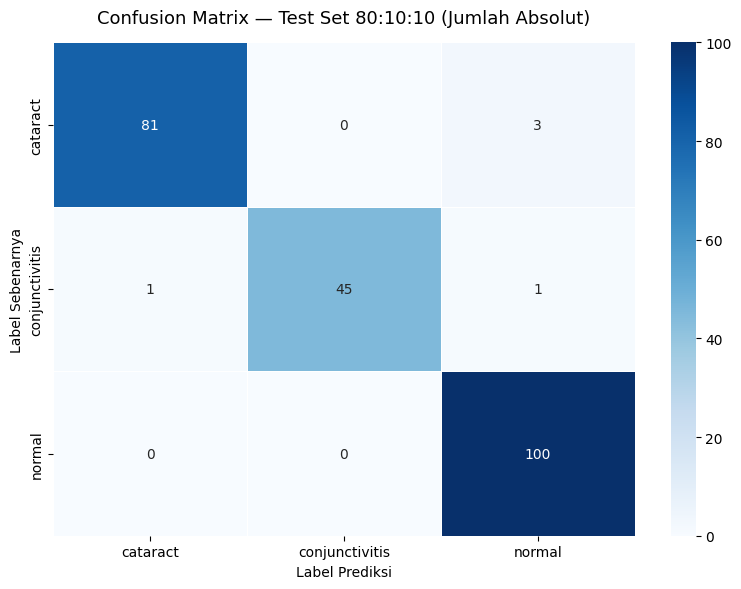

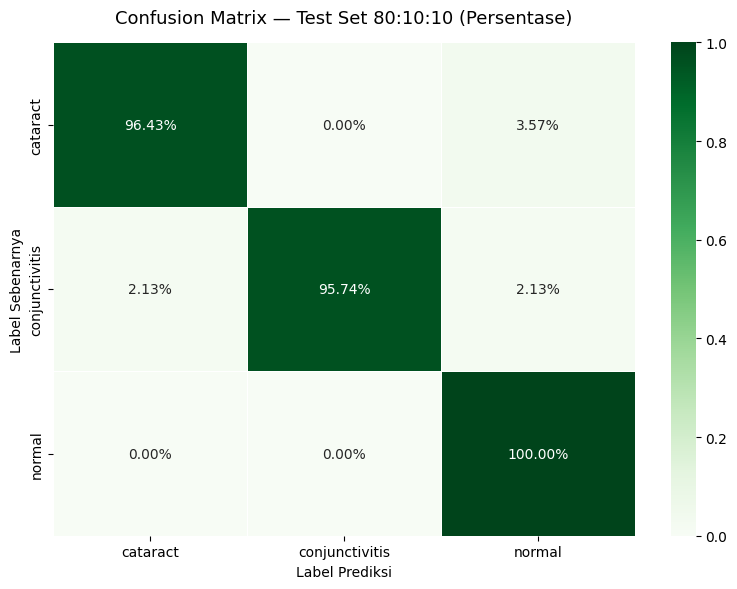

Confusion matrix disimpan: confusion_matrix_80_10_10.png & confusion_matrix_normalised_80_10_10.png


In [ ]:
# ---------------------------------------------------------------------------
# Confusion Matrix — versi jumlah absolut & versi persentase
# ---------------------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5
)
plt.title('Confusion Matrix — Test Set 80:10:10 (Jumlah Absolut)', fontsize=13, pad=14)
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.savefig('/content/confusion_matrix_80_10_10.png', dpi=150, bbox_inches='tight')
plt.show()

cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm, annot=True, fmt='.2%', cmap='Greens',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, vmin=0, vmax=1
)
plt.title('Confusion Matrix — Test Set 80:10:10 (Persentase)', fontsize=13, pad=14)
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.savefig('/content/confusion_matrix_normalised_80_10_10.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix disimpan: confusion_matrix_80_10_10.png & confusion_matrix_normalised_80_10_10.png")

   CLASSIFICATION REPORT — SPLIT 80:10:10
                precision    recall  f1-score   support

      cataract     0.9878    0.9643    0.9759        84
conjunctivitis     1.0000    0.9574    0.9783        47
        normal     0.9615    1.0000    0.9804       100

      accuracy                         0.9784       231
     macro avg     0.9831    0.9739    0.9782       231
  weighted avg     0.9789    0.9784    0.9783       231



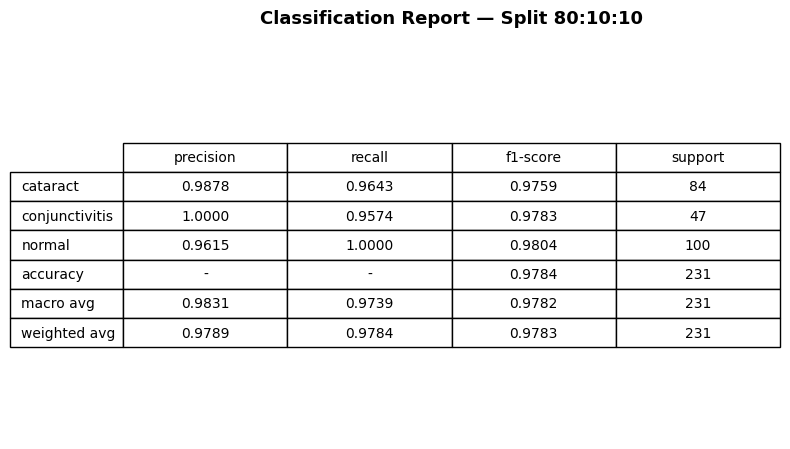

Tabel classification report disimpan: /content/classification_report_80_10_10.png
Verifikasi dengan model.evaluate():
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9784 - loss: 0.0889
  Test Loss     : 0.0889
  Test Accuracy : 0.9784 (97.84%)


In [ ]:
# ---------------------------------------------------------------------------
# Classification Report — Precision, Recall, F1-Score, Support per kelas
# ---------------------------------------------------------------------------
print("=" * 60)
print("   CLASSIFICATION REPORT — SPLIT 80:10:10")
print("=" * 60)
report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4)
print(report_text)
print("=" * 60)

# Simpan juga sebagai gambar tabel rapi untuk lampiran skripsi
report_dict = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)

def plot_classification_report_table(report_dict, class_names, save_path, split_label):
    rows = class_names + ['accuracy', 'macro avg', 'weighted avg']
    cols = ['precision', 'recall', 'f1-score', 'support']

    table_data = []
    for r in rows:
        if r == 'accuracy':
            table_data.append(['-', '-', f"{report_dict['accuracy']:.4f}", int(report_dict['weighted avg']['support'])])
        else:
            d = report_dict[r]
            table_data.append([f"{d['precision']:.4f}", f"{d['recall']:.4f}", f"{d['f1-score']:.4f}", int(d['support'])])

    fig, ax = plt.subplots(figsize=(8, 0.6 * len(rows) + 1))
    ax.axis('off')
    table = ax.table(cellText=table_data, rowLabels=rows, colLabels=cols, loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)
    plt.title(f'Classification Report — Split {split_label}', fontsize=13, pad=20, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Tabel classification report disimpan: {save_path}")

plot_classification_report_table(report_dict, CLASS_NAMES, '/content/classification_report_80_10_10.png', '80:10:10')

# Double-check pakai model.evaluate() bawaan Keras
print("Verifikasi dengan model.evaluate():")
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")

In [ ]:
# Load best model from Phase 2 checkpoint
print("\n[1/4] Loading best model from checkpoint...")
best_model = tf.keras.models.load_model('/content/best_model_phase2_80.keras')
print("      Model loaded successfully")
print(f"      Input shape:  {best_model.input_shape}")
print(f"      Output shape: {best_model.output_shape}")


[1/4] Loading best model from checkpoint...
      Model loaded successfully
      Input shape:  (None, 224, 224, 3)
      Output shape: (None, 3)


In [ ]:
# Quick verification on test set
print("\n[2/4] Verifying model accuracy on test set...")
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"      Test Loss:     {test_loss:.4f}")
print(f"      Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

# Sanity check — make sure this matches what we trained
y_true_check = []
y_pred_check = []
for image_batch, label_batch in test_ds:
    probs = best_model.predict(image_batch, verbose=0)
    y_true_check.extend(tf.argmax(label_batch, axis=1).numpy())
    y_pred_check.extend(np.argmax(probs, axis=1))

from sklearn.metrics import classification_report
print("\n      Per-class results:")
report = classification_report(
    y_true_check, y_pred_check,
    target_names=CLASS_NAMES, digits=4
)
print(report)


[2/4] Verifying model accuracy on test set...
      Test Loss:     0.0889
      Test Accuracy: 0.9784 (97.84%)

      Per-class results:
                precision    recall  f1-score   support

      cataract     0.9878    0.9643    0.9759        84
conjunctivitis     1.0000    0.9574    0.9783        47
        normal     0.9615    1.0000    0.9804       100

      accuracy                         0.9784       231
     macro avg     0.9831    0.9739    0.9782       231
  weighted avg     0.9789    0.9784    0.9783       231



In [ ]:
# Convert to TFLite (float32, no quantization)

print("\n[3/4] Converting to TFLite (float32, no quantization)...")
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)

tflite_model = converter.convert()
print(f"      TFLite model size: {len(tflite_model)/1024/1024:.2f} MB")

# Verify TFLite input/output specs
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print(f"      Input  shape: {input_details[0]['shape']}")
print(f"      Input  dtype: {input_details[0]['dtype']}")
print(f"      Output shape: {output_details[0]['shape']}")
print(f"      Output dtype: {output_details[0]['dtype']}")

# Quick TFLite inference test on one image
sample_batch = next(iter(test_ds))
sample_image = sample_batch[0][0:1].numpy()  # shape [1, 224, 224, 3]

# Preprocess same as training (preprocess_input already applied in model)
# Just verify output
interpreter.set_tensor(input_details[0]['index'], sample_image)
interpreter.invoke()
tflite_output = interpreter.get_tensor(output_details[0]['index'])
keras_output  = best_model.predict(sample_batch[0][0:1], verbose=0)

print(f"\n      TFLite output: {tflite_output[0].round(4)}")
print(f"      Keras  output: {keras_output[0].round(4)}")
print(f"      Match: {np.allclose(tflite_output, keras_output, atol=1e-3)}")





[3/4] Converting to TFLite (float32, no quantization)...
Saved artifact at '/tmp/tmpwzghelju'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  139545838182544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838184272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838179856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838178704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838181392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838177936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838175440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838183696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838179088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139545838179472: TensorSpec

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



      TFLite output: [0.9989 0.     0.0011]
      Keras  output: [0.9989 0.     0.0011]
      Match: True


In [ ]:
# Save all files to Google Drive
print("\n[4/4] Saving files to Google Drive...")
EXPORT_DIR = '/content/drive/MyDrive/aretina_export'
os.makedirs(EXPORT_DIR, exist_ok=True)

# Save TFLite model
tflite_path = os.path.join(EXPORT_DIR, 'eye_model.tflite')
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)
print(f"      ✓ eye_model.tflite → {tflite_path}")

# Save Keras model (backup)
keras_path = os.path.join(EXPORT_DIR, 'eye_model_backup.keras')
best_model.save(keras_path)
print(f"      ✓ eye_model_backup.keras → {keras_path}")

# 4c — Generate labels.txt
labels_path = os.path.join(EXPORT_DIR, 'labels.txt')
with open(labels_path, 'w') as f:
    for class_name in CLASS_NAMES:
        f.write(class_name + '\n')
print(f"      ✓ labels.txt → {labels_path}")

# Summary
print("\n" + "=" * 60)
print(" EXPORT COMPLETE")
print("=" * 60)
print(f"\n Files saved to: {EXPORT_DIR}")
print(f"   eye_model.tflite        ({len(tflite_model)/1024/1024:.2f} MB)")
print(f"   eye_model_backup.keras")
print(f"   labels.txt")

print(f"\n Class order in labels.txt:")
for i, name in enumerate(CLASS_NAMES):
    print(f"   index {i} = {name}")




[4/4] Saving files to Google Drive...
      ✓ eye_model.tflite → /content/drive/MyDrive/aretina_export/eye_model.tflite
      ✓ eye_model_backup.keras → /content/drive/MyDrive/aretina_export/eye_model_backup.keras
      ✓ labels.txt → /content/drive/MyDrive/aretina_export/labels.txt

 EXPORT COMPLETE

 Files saved to: /content/drive/MyDrive/aretina_export
   eye_model.tflite        (9.09 MB)
   eye_model_backup.keras
   labels.txt

 Class order in labels.txt:
   index 0 = cataract
   index 1 = conjunctivitis
   index 2 = normal


In [ ]:
import numpy as np
import pandas as pd

# Gabungkan history phase 1 + phase 2
train_acc = history_p1.history['accuracy'] + history_p2.history['accuracy']
val_acc = history_p1.history['val_accuracy'] + history_p2.history['val_accuracy']

train_loss = history_p1.history['loss'] + history_p2.history['loss']
val_loss = history_p1.history['val_loss'] + history_p2.history['val_loss']

best_epoch = np.argmax(val_acc) + 1

summary = pd.DataFrame({
    "Parameter": [
        "Best Epoch",
        "Training Accuracy",
        "Validation Accuracy",
        "Training Loss",
        "Validation Loss"
    ],
    "Value": [
        best_epoch,
        round(train_acc[best_epoch-1],4),
        round(val_acc[best_epoch-1],4),
        round(train_loss[best_epoch-1],4),
        round(val_loss[best_epoch-1],4)
    ]
})

display(summary)

,Parameter,Value
0,Best Epoch,13.0000
1,Training Accuracy,0.9373
2,Validation Accuracy,0.9868
3,Training Loss,0.1527
4,Validation Loss,0.0747


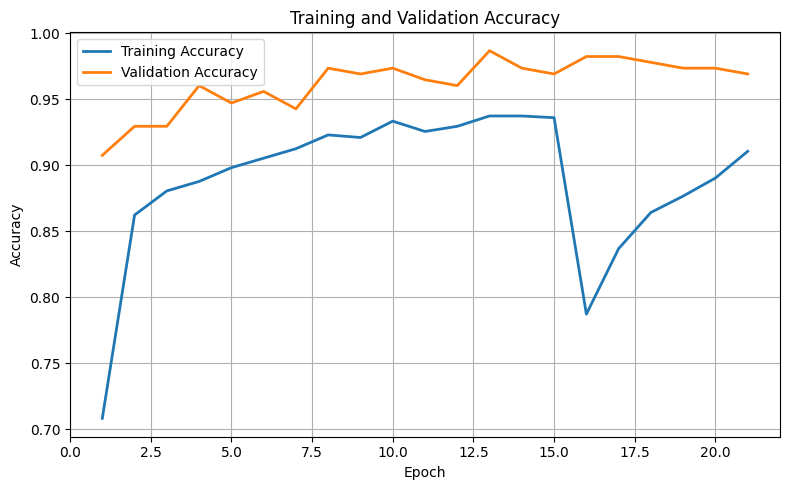

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_acc)+1)

plt.figure(figsize=(8,5))

plt.plot(epochs, train_acc, linewidth=2, label="Training Accuracy")
plt.plot(epochs, val_acc, linewidth=2, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig("accuracy_curve.png", dpi=300)

plt.show()

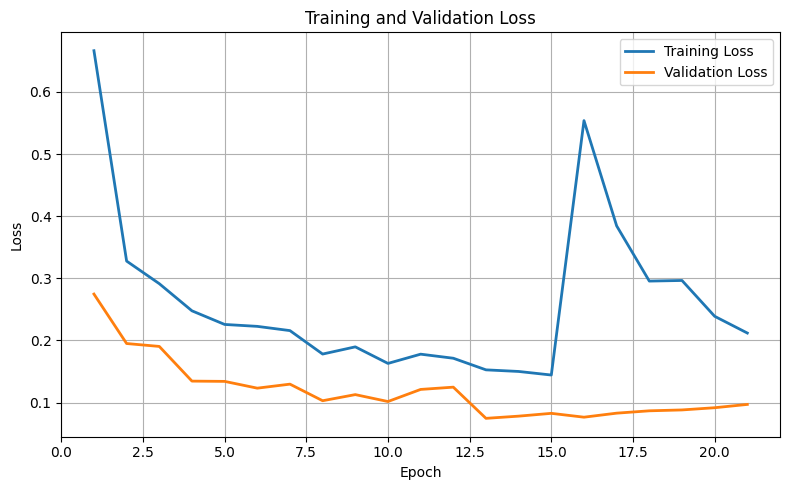

In [ ]:
epochs = range(1, len(train_loss)+1)

plt.figure(figsize=(8,5))

plt.plot(epochs, train_loss, linewidth=2, label="Training Loss")
plt.plot(epochs, val_loss, linewidth=2, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig("loss_curve.png", dpi=300)

plt.show()

In [ ]:
# Training Summary Table
import numpy as np
import pandas as pd

acc = history_p1.history['accuracy'] + history_p2.history['accuracy']
val_acc = history_p1.history['val_accuracy'] + history_p2.history['val_accuracy']

loss = history_p1.history['loss'] + history_p2.history['loss']
val_loss = history_p1.history['val_loss'] + history_p2.history['val_loss']

best_epoch = np.argmax(val_acc) + 1

summary = pd.DataFrame({
    "Parameter":[
        "Best Epoch",
        "Training Accuracy",
        "Validation Accuracy",
        "Training Loss",
        "Validation Loss"
    ],
    "Value":[
        best_epoch,
        round(acc[best_epoch-1],4),
        round(val_acc[best_epoch-1],4),
        round(loss[best_epoch-1],4),
        round(val_loss[best_epoch-1],4)
    ]
})

display(summary)

,Parameter,Value
0,Best Epoch,13.0000
1,Training Accuracy,0.9373
2,Validation Accuracy,0.9868
3,Training Loss,0.1527
4,Validation Loss,0.0747


In [ ]:
# Evaluation Metrics Table
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import pandas as pd

accuracy = accuracy_score(y_true_check, y_pred_check)
precision = precision_score(y_true_check, y_pred_check, average='weighted')
recall = recall_score(y_true_check, y_pred_check, average='weighted')
f1 = f1_score(y_true_check, y_pred_check, average='weighted')

metrics_df = pd.DataFrame({
    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Value":[
        round(accuracy,4),
        round(precision,4),
        round(recall,4),
        round(f1,4)
    ]
})

display(metrics_df)

,Metric,Value
0,Accuracy,0.9784
1,Precision,0.9789
2,Recall,0.9784
3,F1-Score,0.9783


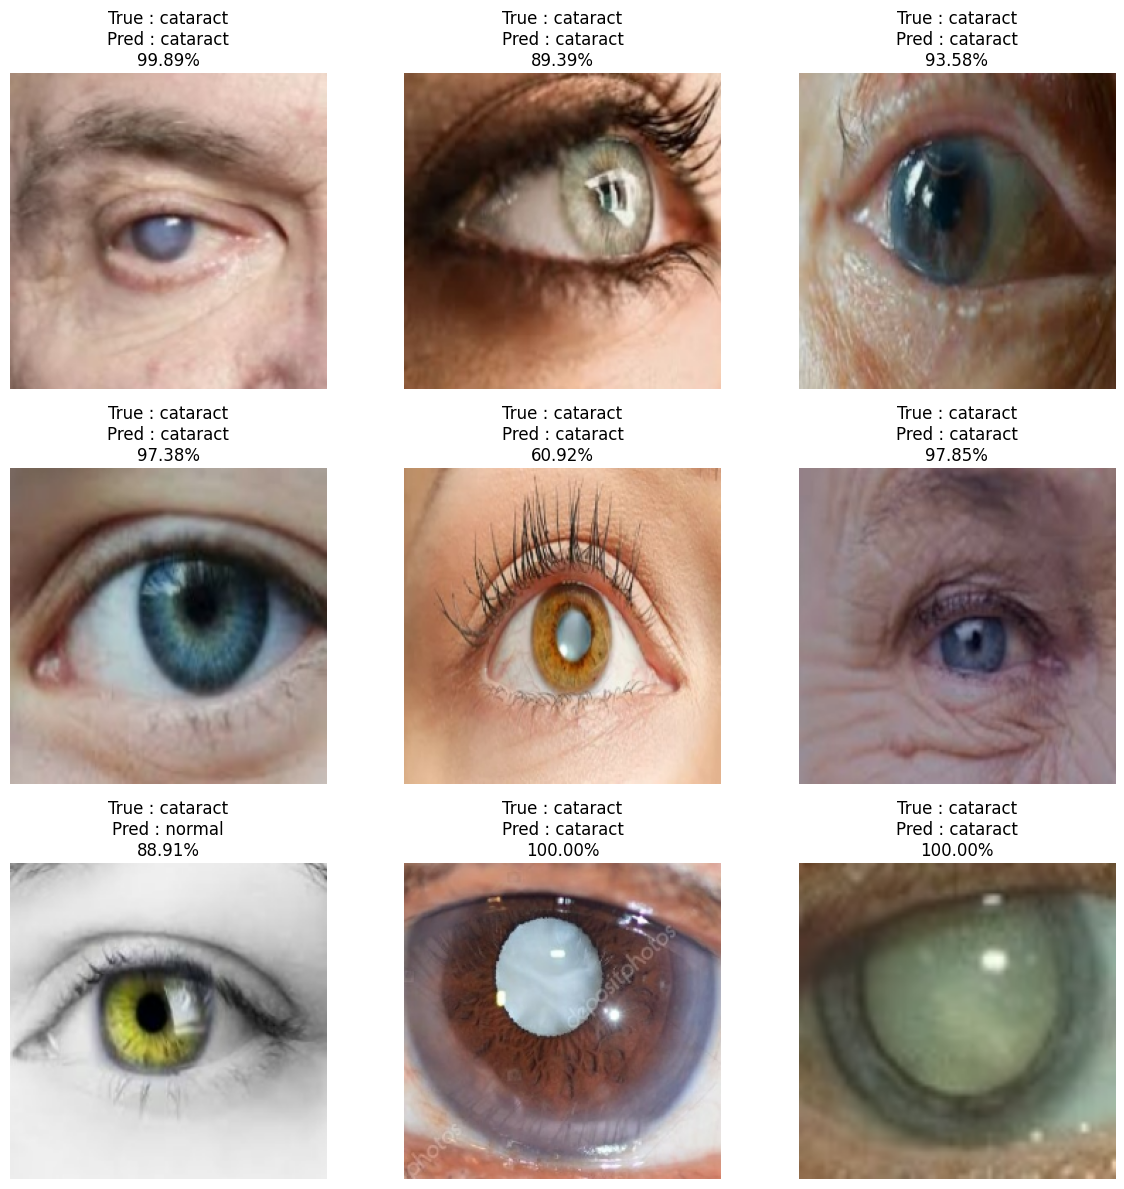

In [ ]:
# Sample Prediction
import matplotlib.pyplot as plt

images, labels = next(iter(test_ds))

predictions = best_model.predict(images, verbose=0)

plt.figure(figsize=(12,12))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(images[i].numpy().astype("uint8"))

    true_label = CLASS_NAMES[tf.argmax(labels[i]).numpy()]
    pred_label = CLASS_NAMES[np.argmax(predictions[i])]
    confidence = np.max(predictions[i]) * 100

    plt.title(
        f"True : {true_label}\n"
        f"Pred : {pred_label}\n"
        f"{confidence:.2f}%"
    )

    plt.axis("off")

plt.tight_layout()
plt.savefig("/content/sample_predictions.png", dpi=300)
plt.show()

In [ ]:
# Model Size
import os

model_size = os.path.getsize("/content/drive/MyDrive/aretina_export/eye_model.tflite") / (1024 * 1024)

print(f"Ukuran model : {model_size:.2f} MB")

Ukuran model : 9.09 MB


In [ ]:
# Inference Time
import time

times = []

sample_image = images[0:1].numpy().astype(np.float32)

for i in range(30):

    start = time.perf_counter()

    interpreter.set_tensor(input_details[0]['index'], sample_image)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])

    end = time.perf_counter()

    times.append((end-start)*1000)

print(f"Rata-rata : {np.mean(times):.2f} ms")
print(f"Minimum   : {np.min(times):.2f} ms")
print(f"Maksimum  : {np.max(times):.2f} ms")

Rata-rata : 7.35 ms
Minimum   : 6.78 ms
Maksimum  : 9.83 ms


In [ ]:
import shutil
import os

EXPORT_DIR = '/content/drive/MyDrive/aretina_export'
os.makedirs(EXPORT_DIR, exist_ok=True)

TEST_DIR = os.path.join(RESPLIT_DIR, 'test')  # /content/dataset_80_10_10/test

# ── 1. Confirm TFLite model existence and size ──────────────────
# The TFLite model was already saved in the previous step (Step 4a in the notebook).
# This section now confirms its presence and reports its size.
tflite_model_path = os.path.join(EXPORT_DIR, 'eye_model.tflite')

# Check if the file exists before trying to get its size
if os.path.exists(tflite_model_path):
    size_mb = os.path.getsize(tflite_model_path) / 1024 / 1024
    print(f"✓ eye_model.tflite is confirmed to be saved at {tflite_model_path} ({size_mb:.2f} MB)")
else:
    print(f"✗ Error: eye_model.tflite not found at {tflite_model_path}")

✓ eye_model.tflite is confirmed to be saved at /content/drive/MyDrive/aretina_export/eye_model.tflite (9.09 MB)


In [ ]:
# ── 2. Generate labels.txt ────────────────────────────────────────
# CLASS_NAMES from your notebook is already sorted alphabetically
# ['cataract', 'conjunctivitis', 'normal']
labels_path = os.path.join(EXPORT_DIR, 'labels.txt')
with open(labels_path, 'w') as f:
    for name in CLASS_NAMES:
        f.write(name + '\n')
print(f"✓ labels.txt saved")
print(f"  Order: {list(enumerate(CLASS_NAMES))}")

✓ labels.txt saved
  Order: [(0, 'cataract'), (1, 'conjunctivitis'), (2, 'normal')]


In [ ]:
# ── 3. Save 10 demo images per class from test set ───────────────
DEMO_DIR = os.path.join(EXPORT_DIR, 'demo_images')
for class_name in CLASS_NAMES:
    src_dir  = os.path.join(TEST_DIR, class_name)
    dest_dir = os.path.join(DEMO_DIR, class_name)
    os.makedirs(dest_dir, exist_ok=True)

    images = sorted(os.listdir(src_dir))[:10]
    for img_name in images:
        shutil.copy(
            os.path.join(src_dir, img_name),
            os.path.join(dest_dir, img_name)
        )
    print(f"✓ demo_images/{class_name}: {len(images)} images saved")

✓ demo_images/cataract: 10 images saved
✓ demo_images/conjunctivitis: 10 images saved
✓ demo_images/normal: 10 images saved


In [ ]:
# ── 4. Summary ────────────────────────────────────────────────────
print(f"""
{'='*55}
 DONE — Files saved to Drive/aretina_export/
{'='*55}

 eye_model.tflite  → Flutter: assets/model/eye_model.tflite
 labels.txt        → Flutter: assets/model/labels.txt
 demo_images/      → Transfer to phone for testing

 Class order in labels.txt:
   index 0 = {CLASS_NAMES[0]}
   index 1 = {CLASS_NAMES[1]}
   index 2 = {CLASS_NAMES[2]}

 Flutter constants.dart must have:
   diseaseLabels = {CLASS_NAMES}
   (capitalize first letter of each)
{'='*55}
""")


 DONE — Files saved to Drive/aretina_export/

 eye_model.tflite  → Flutter: assets/model/eye_model.tflite
 labels.txt        → Flutter: assets/model/labels.txt
 demo_images/      → Transfer to phone for testing

 Class order in labels.txt:
   index 0 = cataract
   index 1 = conjunctivitis
   index 2 = normal

 Flutter constants.dart must have:
   diseaseLabels = ['cataract', 'conjunctivitis', 'normal']
   (capitalize first letter of each)

